<a href="https://colab.research.google.com/github/1322vishav/Image-Processing/blob/main/Assignment6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
from google.colab import drive
drive.mount('/content/drive')

import cv2
import numpy as np
import matplotlib.pyplot as plt

IMG_PATH = '/content/drive/MyDrive/image.jpg'

gray = cv2.imread(IMG_PATH, cv2.IMREAD_GRAYSCALE)
if gray is None:
    raise FileNotFoundError(f"Could not read {IMG_PATH}")

def to_u8(a):
    return np.clip(a, 0, 255).astype(np.uint8)

print("Image shape:", gray.shape)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Image shape: (720, 1280)


In [3]:
def averaging_kernel(k):
    return np.ones((k, k)) / (k * k)

def weighted_kernel(k):
    r = k // 2
    x, y = np.meshgrid(np.arange(-r, r + 1), np.arange(-r, r + 1))
    h = np.maximum(np.abs(x), np.abs(y)).astype(np.float64)
    return h / h.sum()

def gaussian_kernel(k, sigma):
    r = k // 2
    x, y = np.meshgrid(np.arange(-r, r + 1), np.arange(-r, r + 1))
    g = np.exp(-(x ** 2 + y ** 2) / (2 * sigma ** 2))
    return g / g.sum()

def convolve(img, kernel, pad_mode):
    k = kernel.shape[0]
    p = k // 2
    h, w = img.shape
    padded = np.pad(img.astype(np.float64), p, mode=pad_mode)
    out = np.zeros((h, w))
    for i in range(k):
        for j in range(k):
            out += kernel[i, j] * padded[i:i + h, j:j + w]
    return out

In [4]:
k = int(input("Filter size (odd, >= 3): "))
if k % 2 == 0 or k < 3:
    raise ValueError("Filter size must be odd and >= 3")

sigma = float(input("Sigma for Gaussian filter: "))

choice = input("Padding method (zero / replicate / reflect / wrap): ").strip().lower()
pad_modes = {'zero': 'constant', 'replicate': 'edge', 'reflect': 'reflect', 'wrap': 'wrap'}
if choice not in pad_modes:
    raise ValueError("Padding must be one of: zero, replicate, reflect, wrap")
pad = pad_modes[choice]

avg = to_u8(convolve(gray, averaging_kernel(k), pad))
wtd = to_u8(convolve(gray, weighted_kernel(k), pad))
gau = to_u8(convolve(gray, gaussian_kernel(k, sigma), pad))

if k <= 7:
    print("\nWeighted kernel:\n", np.round(weighted_kernel(k), 4))
    print("\nGaussian kernel:\n", np.round(gaussian_kernel(k, sigma), 4))

Filter size (odd, >= 3): 15
Sigma for Gaussian filter: 3
Padding method (zero / replicate / reflect / wrap): replicate


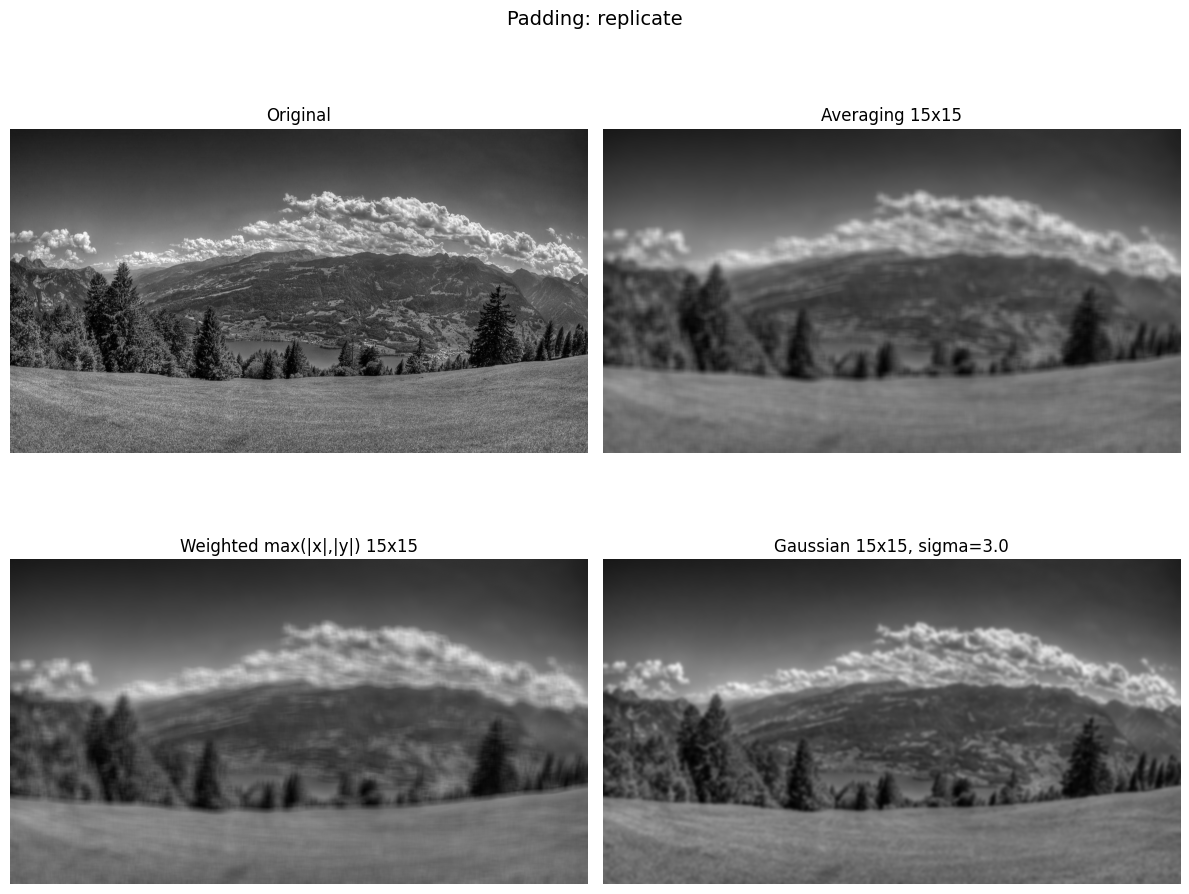

In [5]:
fig, ax = plt.subplots(2, 2, figsize=(12, 10))
items = [(gray, 'Original'),
         (avg, f'Averaging {k}x{k}'),
         (wtd, f'Weighted max(|x|,|y|) {k}x{k}'),
         (gau, f'Gaussian {k}x{k}, sigma={sigma}')]

for a, (im, t) in zip(ax.ravel(), items):
    a.imshow(im, cmap='gray', vmin=0, vmax=255)
    a.set_title(t)
    a.axis('off')

plt.suptitle(f'Padding: {choice}', fontsize=14)
plt.tight_layout()
plt.show()